# DIP-VAE

Regularize the aggregate posterior covariance toward the identity. This notebook uses a DIP-VAE-II style covariance estimate and separately weights off-diagonal and diagonal penalties.

This standalone notebook includes its own MNIST setup, model components, objective, and training step. Run the cells from top to bottom. The training cell runs 50 epochs on the full MNIST training split. A GPU runtime is recommended in Colab.

## Shared MNIST data and VAE components

The baseline is a small MLP VAE with a diagonal Gaussian posterior and Bernoulli image decoder. We reuse it where the variant changes the objective rather than the architecture.

In [1]:
import math
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')
transform = transforms.ToTensor()
train_data = datasets.MNIST('data', train=True, download=True, transform=transform)
test_data = datasets.MNIST('data', train=False, download=True, transform=transform)
train_loader = DataLoader(train_data, batch_size=128, shuffle=True)
test_loader = DataLoader(test_data, batch_size=128, shuffle=False)

class MLPVAE(nn.Module):
    def __init__(self, latent_dim=16):
        super().__init__(); self.latent_dim = latent_dim
        self.encoder = nn.Sequential(nn.Linear(784, 400), nn.ReLU())
        self.mu = nn.Linear(400, latent_dim); self.logvar = nn.Linear(400, latent_dim)
        self.decoder = nn.Sequential(nn.Linear(latent_dim, 400), nn.ReLU(), nn.Linear(400, 784), nn.Sigmoid())
    def encode(self, x):
        h = self.encoder(x.flatten(1)); return self.mu(h), self.logvar(h)
    def reparameterize(self, mu, logvar):
        return mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)
    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)
    def forward(self, x):
        mu, logvar = self.encode(x); z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar

def vae_terms(recon, x, mu, logvar):
    rec = F.binary_cross_entropy(recon, x, reduction='none').flatten(1).sum(1).mean()
    kl = -0.5 * (1 + logvar - mu.square() - logvar.exp()).sum(1).mean()
    return rec, kl

def sample_batch(loader):
    return next(iter(loader))[0].to(device)

Using device: cuda


## Implementation

The following cell defines this variant's model-specific objective and optimization step.

## 4. DIP-VAE

DIP-VAE penalizes deviations between aggregate-posterior covariance and the identity covariance of a standard normal prior. Here we use a DIP-VAE-II style estimate: `Cov(mu(x)) + mean_x[diag(var(z|x))]`. We penalize off-diagonal covariance and the diagonal's distance from one. This encourages uncorrelated dimensions; zero covariance alone does not imply full independence.

In [2]:
dip_vae = MLPVAE().to(device); dip_optim = torch.optim.Adam(dip_vae.parameters(), lr=1e-3)

def dip_covariance(mu, logvar):
    centered = mu - mu.mean(dim=0, keepdim=True)
    cov_mu = centered.T @ centered / max(mu.size(0) - 1, 1)
    cov_q = cov_mu + torch.diag(torch.exp(logvar).mean(dim=0))
    return cov_q

def dipvae_train_step(x, lambda_off=10.0, lambda_diag=1.0):
    x = x.to(device); recon, mu, logvar = dip_vae(x); rec, kl = vae_terms(recon, x, mu, logvar)
    cov = dip_covariance(mu, logvar); eye = torch.eye(cov.size(0), device=device)
    off_diag = cov - torch.diag(torch.diag(cov))
    reg = lambda_off * off_diag.square().sum() + lambda_diag * (torch.diag(cov) - 1).square().sum()
    loss = rec + kl + reg
    dip_optim.zero_grad(); loss.backward(); dip_optim.step()
    return {'reconstruction': rec.item(), 'kl': kl.item(), 'covariance_penalty': reg.item()}

# Example: metrics = dipvae_train_step(sample_batch(train_loader))

## Full training — 50 epochs

This runs on the full MNIST training split using the model-specific objective above. In Colab, select a GPU runtime for faster training. The final checkpoint includes model weights, optimizer state, and epoch metrics.

In [3]:
from pathlib import Path

epochs = 50
history = []
for epoch in range(1, epochs + 1):
    totals = {}
    for images, _ in train_loader:
        batch_metrics = dipvae_train_step(images)
        for name, value in batch_metrics.items():
            totals[name] = totals.get(name, 0.0) + float(value) * images.size(0)
    epoch_metrics = {name: value / len(train_loader.dataset) for name, value in totals.items()}
    history.append(epoch_metrics)
    summary = " | ".join(f"{name}={value:.4f}" for name, value in epoch_metrics.items())
    print(f"Epoch {epoch:02d}/{epochs} | {summary}")

checkpoint = {
    "model": dip_vae.state_dict(),
    "optimizers": {"dip_optim": dip_optim.state_dict()},
    "epochs": epochs,
    "history": history
}
checkpoint_path = Path("12_DIP_VAE_50_epochs.pt")
torch.save(checkpoint, checkpoint_path)
print(f"Saved checkpoint to {checkpoint_path.resolve()}")


Epoch 01/50 | reconstruction=159.8361 | kl=11.0902 | covariance_penalty=4.2027
Epoch 02/50 | reconstruction=112.8388 | kl=16.1763 | covariance_penalty=5.7712
Epoch 03/50 | reconstruction=103.5108 | kl=17.5435 | covariance_penalty=5.6944
Epoch 04/50 | reconstruction=99.3793 | kl=18.2423 | covariance_penalty=5.5636
Epoch 05/50 | reconstruction=96.8853 | kl=18.6741 | covariance_penalty=5.3856
Epoch 06/50 | reconstruction=95.2353 | kl=18.9850 | covariance_penalty=5.3886
Epoch 07/50 | reconstruction=94.0120 | kl=19.1790 | covariance_penalty=5.4166
Epoch 08/50 | reconstruction=93.0221 | kl=19.3745 | covariance_penalty=5.3587
Epoch 09/50 | reconstruction=92.2267 | kl=19.4909 | covariance_penalty=5.3212
Epoch 10/50 | reconstruction=91.5960 | kl=19.6005 | covariance_penalty=5.3202
Epoch 11/50 | reconstruction=90.9934 | kl=19.7075 | covariance_penalty=5.3137
Epoch 12/50 | reconstruction=90.4537 | kl=19.8143 | covariance_penalty=5.3425
Epoch 13/50 | reconstruction=90.0070 | kl=19.8861 | covarianc

## Inspect reconstructions and aggregate covariance

Use these plots alongside the objective metrics; no single number captures reconstruction quality, prior matching, latent use, and sample quality.

Aggregate posterior covariance diagonal: [0.4620000123977661, 0.6320000290870667, 0.5839999914169312, 0.5379999876022339, 0.972000002861023, 0.9940000176429749, 0.699999988079071, 0.8510000109672546, 0.9940000176429749, 0.5989999771118164, 0.7459999918937683, 0.5590000152587891, 0.6869999766349792, 1.0119999647140503, 0.9850000143051147, 0.6859999895095825]


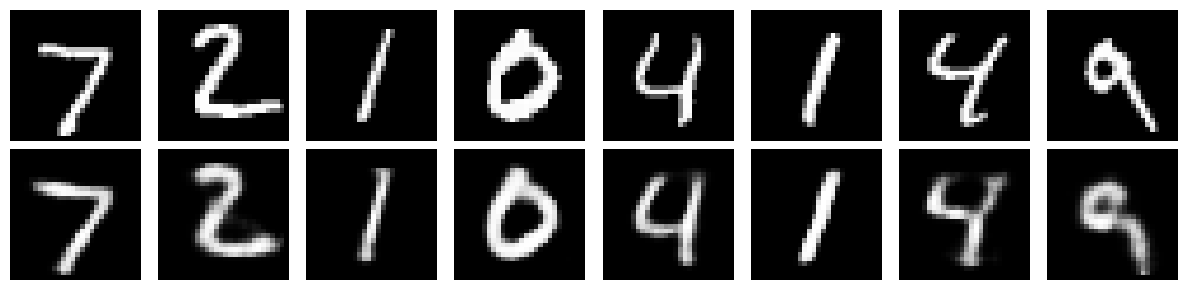

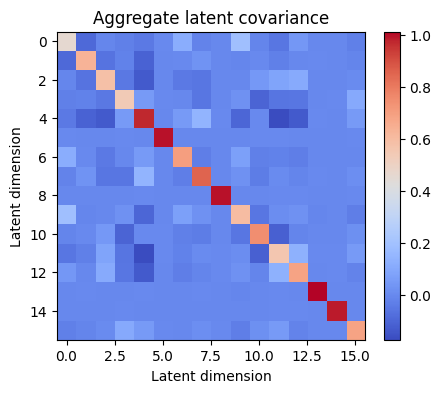

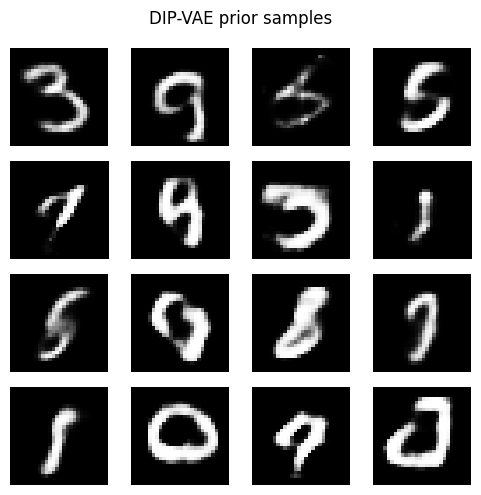

In [4]:
x = sample_batch(test_loader)[:8]
dip_vae.eval()
with torch.no_grad():
    mu, logvar = dip_vae.encode(x); recon = dip_vae.decode(dip_vae.reparameterize(mu, logvar))
    prior_samples = dip_vae.decode(torch.randn(16, dip_vae.latent_dim, device=device))
    z_mu, z_lv = dip_vae.encode(sample_batch(test_loader))
    cov = dip_covariance(z_mu, z_lv).cpu()
print('Aggregate posterior covariance diagonal:', cov.diag().round(decimals=3).tolist())
fig, axes = plt.subplots(2, 8, figsize=(12, 3))
for i in range(8):
    axes[0, i].imshow(x[i, 0].cpu(), cmap='gray'); axes[0, i].axis('off')
    axes[1, i].imshow(recon[i, 0].cpu(), cmap='gray'); axes[1, i].axis('off')
axes[0, 0].set_ylabel('Input'); axes[1, 0].set_ylabel('Reconstruction')
plt.tight_layout(); plt.show()
plt.figure(figsize=(5, 4)); plt.imshow(cov, cmap='coolwarm'); plt.colorbar(); plt.title('Aggregate latent covariance'); plt.xlabel('Latent dimension'); plt.ylabel('Latent dimension'); plt.show()
fig, axes = plt.subplots(4, 4, figsize=(5, 5))
for ax, image in zip(axes.flat, prior_samples):
    ax.imshow(image[0].cpu(), cmap='gray'); ax.axis('off')
plt.suptitle('DIP-VAE prior samples'); plt.tight_layout(); plt.show()